In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

DATA = "/content/drive/MyDrive/Colab_Notebooks/Y3/COIS-3060/Assign2/data"

from google.colab import drive
drive.mount('/content/drive')

# Apply Seaborn styling
sns.set_theme(style="white")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [62]:
# --- Load DF ---
issue_df = pd.read_csv(os.path.join(DATA,"issues.csv"))
issue_comments_df = pd.read_csv(os.path.join(DATA,"issue_comments.csv"))

## Exploratory Data Analysis

---

This section is aimed at understanding the structure of the dataset we will be using and justifiying preprocessing decisions

### issues.csv EDA

In [63]:
# --- Issue DF ---
print(f'Number of columns: {len(issue_df.columns)}')
print(f'Number of rows: {len(issue_df)}\n')
issue_df

Number of columns: 39
Number of rows: 5000



,issue_id,repo_name,issue_number,title,body,state_final,author_login,agent_type,n_gharchive_events,comments_count_reported,...,reactions_laugh,reactions_hooray,reactions_confused,reactions_heart,reactions_rocket,reactions_eyes,n_labels,n_assignees,labels,n_comments_actual
0,01capitain/jira-release-manager#66,01capitain/jira-release-manager,66,Add pre-commit hooks for eslint and schema val...,## Problem\n\nSchema validation rules (like th...,open,coderabbitai[bot],CodeRabbit,1,NaN,...,0,0,0,0,0,0,0,1,NaN,0
1,01capitain/jira-release-manager#67,01capitain/jira-release-manager,67,Add Next.js Link component guideline to UI doc...,"## Context\n\nBased on discussion in PR #64, w...",open,coderabbitai[bot],CodeRabbit,1,NaN,...,0,0,0,0,0,0,0,1,NaN,0
2,01fe23bcs183/indietix#102,01fe23bcs183/indietix,102,[AUDIT] Marketing package build failing on mai...,## Context\n\n**Discovered during:** PR audit ...,closed,devin-ai-integration[bot],Devin,1,NaN,...,0,0,0,0,0,0,1,0,bug,0
3,01fe23bcs183/indietix#92,01fe23bcs183/indietix,92,[AUDIT] CI Failure: PR #53 merged with failing...,## Context\n\n**PR:** #53 - [refunds] Cancella...,open,devin-ai-integration[bot],Devin,1,NaN,...,0,0,0,0,0,0,1,0,bug,0
4,01fe23bcs183/indietix#94,01fe23bcs183/indietix,94,[AUDIT] CI Failure: PR #51 merged with failing...,## Context\n\n**PR:** #51 - [book] Booking cor...,open,devin-ai-integration[bot],Devin,1,NaN,...,0,0,0,0,0,0,1,0,bug,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,liberu-genealogy/genealogy-laravel#767,liberu-genealogy/genealogy-laravel,767,Sweep: add stripe support using laravel cashie...,### Details\n\n_No response_,closed,curtisdelicata,Sweep,2,NaN,...,0,0,1,0,0,1,1,0,sweep,1
4996,JokerTrickster/board_game_app#28,JokerTrickster/board_game_app,28,Epic: Week 3 - Navigation Improvements (네비게이션 개선),# Epic: Week 3 - Navigation Improvements\n\n##...,open,JokerTrickster,Claude_Code,1,NaN,...,0,0,0,0,0,0,0,0,NaN,0
4997,davideast/jules-sdk-python#249,davideast/jules-sdk-python,249,[Fleet Execution] [Create Inspect Source Snippet],### Goal Reference\nThis issue was generated f...,open,davideast,Jules,1,NaN,...,0,0,0,0,0,0,1,0,fleet,0
4998,aws/aws-toolkit-visual-studio#596,aws/aws-toolkit-visual-studio,596,Usage analytics/report for Amazon Q Developer,Description:\n\nAs a developer using Amazon Q ...,open,sanket27sonukadam,Amazon_Q,1,NaN,...,0,0,0,0,0,0,1,0,feature-request,0


Text(0.5, 1.0, 'Heatmap Distribution for issues.csv')

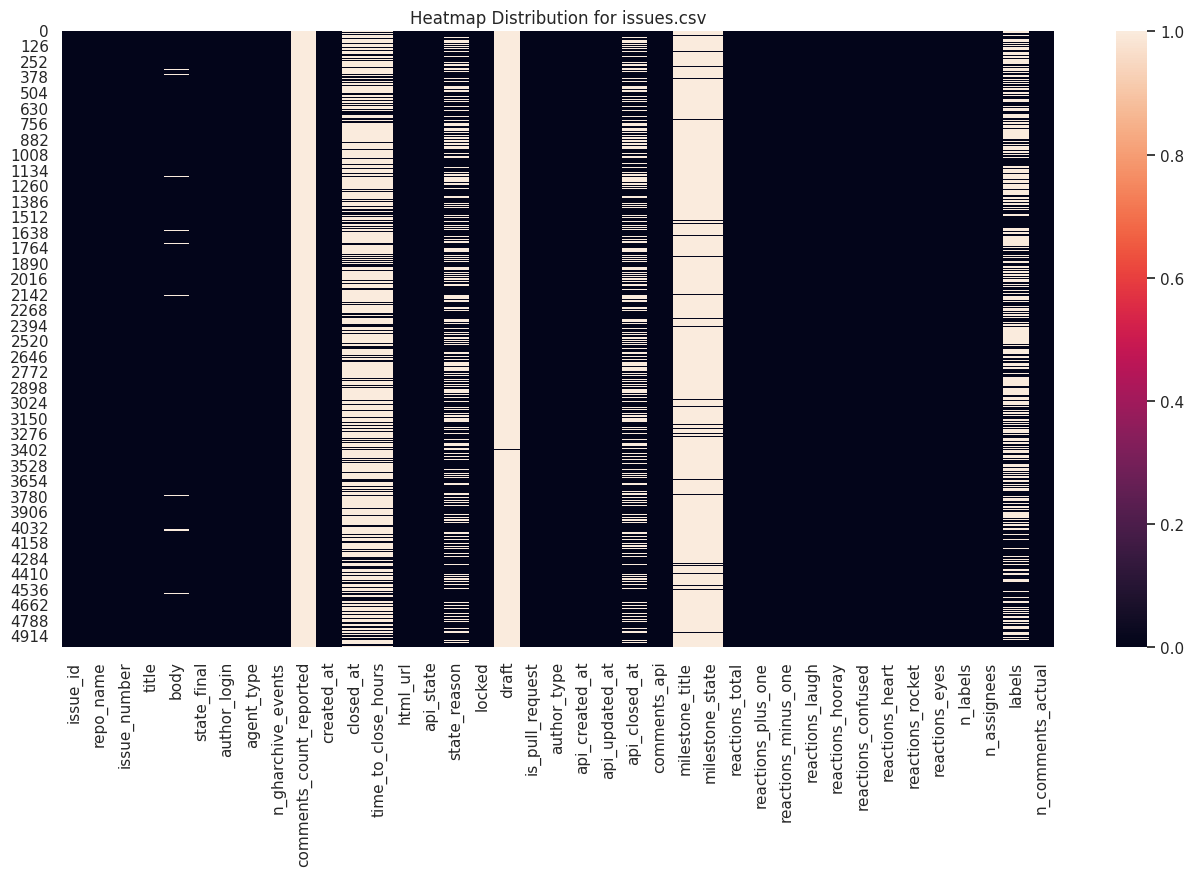

In [64]:
# --- Visualize NaN Values ---
plt.figure(figsize=(16,8))
sns.heatmap(issue_df.isna())
plt.title("Heatmap Distribution for issues.csv")

In [65]:
# --- Assess NaN Values ---
nan_df = pd.DataFrame({
    "Column": issue_df.columns,
    "NaN Count": issue_df.isna().sum().values,
    "NaN Percentage (%)": (issue_df.isna().mean() * 100).round(2).values
}).sort_values( by="NaN Percentage (%)", ascending=False).reset_index(drop=True)
nan_df

,Column,NaN Count,NaN Percentage (%)
0,comments_count_reported,5000,100.00
1,draft,4982,99.64
2,milestone_state,4806,96.12
3,milestone_title,4806,96.12
4,time_to_close_hours,3693,73.86
5,closed_at,3693,73.86
6,labels,2522,50.44
7,api_closed_at,1691,33.82
8,state_reason,1672,33.44
9,body,129,2.58


### Analysis (issues.csv)

As seen from the NaN values plot and dataframe, a substantial number of columns have a large number of missing values. For columns such as `comments_count_reported`,`draft`, `milestone_state`, `milestone_title`, `closed_at` which contain over 70% missing values, imputation would lead to serve bias. For these columns we will simply remove them.

For `time_to_close_hours` which is required to answer RQ2 we will drop all NaN rows. The reasons behind this is that imputation on this column would introduce massive bias as we would be using 25% of the data to represent the other 75%.  

For `api_closed_at` column, given our task is to analyze reasons issues get closed, we will remove all rows where `api_closed_at` is NA which means the issue has not been closed

`label` we will encode all NaN values in this `not resolved`.

`state_reason` provides the reason a github issue was closed. For the analysis we are performing this is a crucial feature, to avoid bias we will remove all values that are NA

`body`, since only a small portion of these values or NaN, we will replace all NaN values with "empty"

### issue_comments.csv EDA

In [66]:
print(f'Number of columns: {len(issue_comments_df.columns)}')
print(f'Number of rows: {len(issue_comments_df)}\n')
issue_comments_df

Number of columns: 8
Number of rows: 1468



,comment_id,issue_id,issue_number,repo_name,body,author_login,agent_type,created_at
0,1873421835,mdtanrikulu/mhmdt.com#14,14,mdtanrikulu/mhmdt.com,"<div align='center'><a href=""https://github.co...",ironic-iterator[bot],Sweep,2024-01-01 18:04:06+00:00
1,1873582852,gwicho38/lsh#5,5,gwicho38/lsh,"<div align='center'><a href=""https://github.co...",sweep-ai[bot],Sweep,2024-01-02 02:54:59+00:00
2,1874146523,xoo-creative/flash#48,48,xoo-creative/flash,"<div align='center'><a href=""https://github.co...",sweep-ai[bot],Sweep,2024-01-02 15:08:25+00:00
3,1874732276,MrIbrahem/wd-core#62,62,MrIbrahem/wd-core,"<div align='center'><a href=""https://github.co...",sweep-ai[bot],Sweep,2024-01-03 00:50:21+00:00
4,1874777672,jofftiquez/jofftiquez.dev#18,18,jofftiquez/jofftiquez.dev,"<div align='center'><a href=""https://github.co...",sweep-ai[bot],Sweep,2024-01-03 02:28:14+00:00
...,...,...,...,...,...,...,...,...
1463,4229778379,carlos-emr/carlos#1554,1554,carlos-emr/carlos,<!-- This is an auto-generated issue plan by C...,coderabbitai[bot],CodeRabbit,2026-04-11 16:41:56+00:00
1464,4229965648,VilnaCRM-Org/bootstrap-infrastructure#5,5,VilnaCRM-Org/bootstrap-infrastructure,<!-- This is an auto-generated issue plan by C...,coderabbitai[bot],CodeRabbit,2026-04-11 18:38:17+00:00
1465,4230429906,EvilBit-Labs/gold_digger#182,182,EvilBit-Labs/gold_digger,<!-- This is an auto-generated issue plan by C...,coderabbitai[bot],CodeRabbit,2026-04-12 00:21:24+00:00
1466,4232818860,harishkamathuk/media-manager#87,87,harishkamathuk/media-manager,<!-- This is an auto-generated issue plan by C...,coderabbitai[bot],CodeRabbit,2026-04-12 21:51:57+00:00


Text(0.5, 1.0, 'Heatmap Distribution for issues_comments.csv')

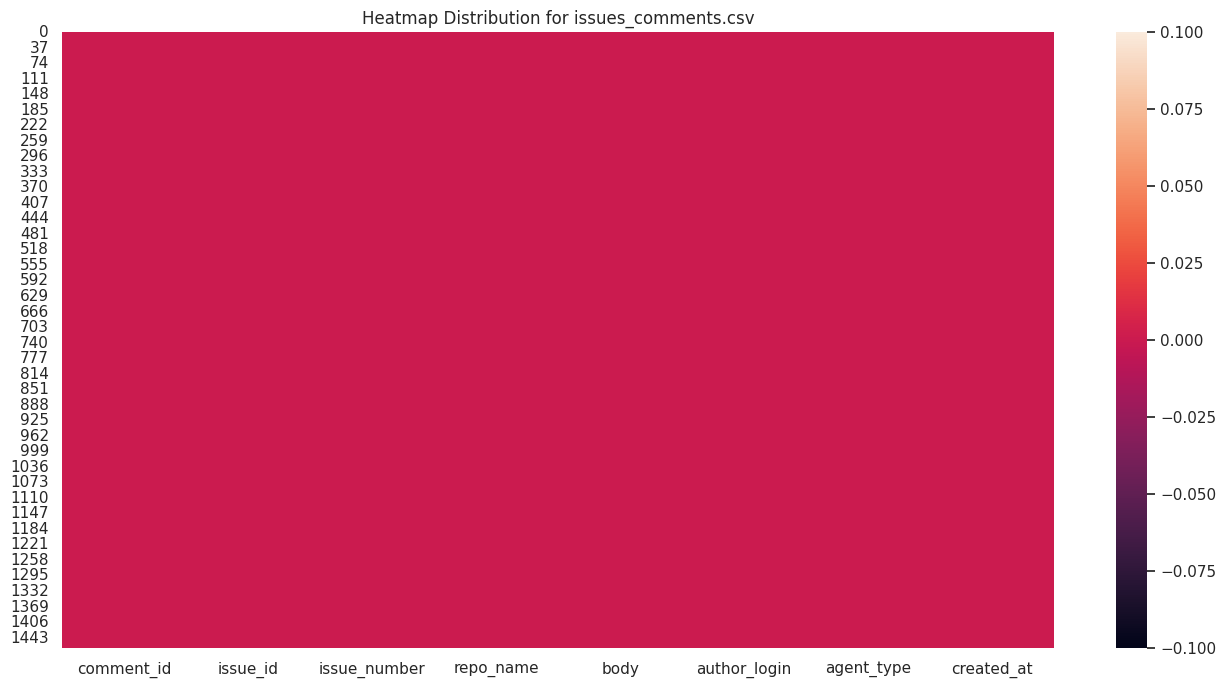

In [67]:
# --- Visualize NaN Values ---
plt.figure(figsize=(16,8))
sns.heatmap(issue_comments_df.isna())
plt.title("Heatmap Distribution for issues_comments.csv")

In [68]:
# --- Assess NaN Values ---
nan_df = pd.DataFrame({
    "Column": issue_comments_df.columns,
    "NaN Count": issue_comments_df.isna().sum().values,
    "NaN Percentage (%)": (issue_comments_df.isna().mean() * 100).round(2).values
}).sort_values( by="NaN Percentage (%)", ascending=False).reset_index(drop=True)
nan_df

,Column,NaN Count,NaN Percentage (%)
0,comment_id,0,0.0
1,issue_id,0,0.0
2,issue_number,0,0.0
3,repo_name,0,0.0
4,body,0,0.0
5,author_login,0,0.0
6,agent_type,0,0.0
7,created_at,0,0.0


### Analysis (issues_comment.csv)

As seen from the NaN values plot and dataframe, a the `issues_comment.csv` does not contain any NaN values, meaning no imputation strategy is required.

For the sake of our research questions, the only columns we will utilize are
`comment_id`,`issue_id`, `create_at`

## Preprocessing Functions

---

The functions below automated the EDA analysis discussed above

In [69]:
def preprocess_issues(data_dir:str = DATA):
    # Load csv's
    issue_df = pd.read_csv(os.path.join(DATA,"issues.csv"))

    issue_df = issue_df.drop(columns=["comments_count_reported","draft","milestone_state","milestone_title","closed_at"],axis=1)
    issue_df = issue_df.dropna(subset=["time_to_close_hours"])
    issue_df = issue_df.dropna(subset=["api_closed_at"])
    issue_df["labels"] = issue_df["labels"].fillna("not resolved")
    issue_df = issue_df.dropna(subset=["state_reason"])
    issue_df["body"] = issue_df["body"].fillna("empty")

    return issue_df

issue_df = preprocess_issues()
print(f'Number of columns: {len(issue_df.columns)}')
print(f'Number of rows: {len(issue_df)}\n')
issue_df

Number of columns: 34
Number of rows: 1292



,issue_id,repo_name,issue_number,title,body,state_final,author_login,agent_type,n_gharchive_events,created_at,...,reactions_laugh,reactions_hooray,reactions_confused,reactions_heart,reactions_rocket,reactions_eyes,n_labels,n_assignees,labels,n_comments_actual
2,01fe23bcs183/indietix#102,01fe23bcs183/indietix,102,[AUDIT] Marketing package build failing on mai...,## Context\n\n**Discovered during:** PR audit ...,closed,devin-ai-integration[bot],Devin,1,2025-11-03 12:43:09+00:00,...,0,0,0,0,0,0,1,0,bug,0
5,094459/aqd-workshop#2,094459/aqd-workshop,2,"step2 Amazon Q Developer Log: ""Amazon Q"" optio...",> You can access the various Amazon Q Develope...,closed,ymotongpoo,Amazon_Q,2,2025-03-04 07:15:23+00:00,...,0,0,0,0,0,0,0,0,not resolved,0
6,0x7o/SimpleBlogSite#2,0x7o/SimpleBlogSite,2,Sweep: Add image uploading when publishing a post,Customize Django to upload images to the post....,closed,0x7o,Sweep,2,2024-05-30 07:43:32+00:00,...,0,0,0,0,1,1,1,0,sweep,1
8,0xHoneyJar/loa#198,0xHoneyJar/loa,198,research: Loa Framework Optimization Opportuni...,## Overview\n\nDeep codebase investigation ide...,closed,janitooor,Claude_Code,1,2026-02-05 13:13:55+00:00,...,0,0,0,0,0,0,0,0,not resolved,0
22,2hanbyeol1/searchright-blog#2,2hanbyeol1/searchright-blog,2,241204 피드백 반영,> [24.12.04 테스트](https://searchright.net/blog/...,closed,2hanbyeol1,CodeRabbit,1,2024-12-10 12:43:39+00:00,...,0,0,0,0,0,0,2,1,bug;feature,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4984,rjwalters/vibesql#1247,rjwalters/vibesql,1247,Fix commutative property handling with indexes...,## Problem\n\nThe `index/commute/*` test categ...,closed,rjwalters,Claude_Code,3,2025-11-11 02:23:53+00:00,...,0,0,0,0,0,0,1,0,loom:building,0
4986,yykamei/block-merge-based-on-time#2435,yykamei/block-merge-based-on-time,2435,GitHub Workflow Metrics on Tue Jul 08 2025,\n```mermaid\n---\nconfig:\n xyChart:\n ...,closed,github-actions[bot],SWE_agent,2,2025-07-08 08:07:45+00:00,...,0,0,0,0,0,0,1,0,github-workflows-metrics,0
4991,stevenson-space/shs#398,stevenson-space/shs,398,bug: ConfirmPopup concurrent calls leave promi...,**Severity:** Major\n\n**File:** `src/componen...,closed,coderabbitai[bot],CodeRabbit,1,2026-02-27 20:51:07+00:00,...,0,0,0,0,0,0,0,1,not resolved,0
4994,anthropics/claude-code#617,anthropics/claude-code,617,[FEATURE REQUEST] Allow disabling Claude attri...,## Environment\n- Platform (select one):\n - ...,closed,mackermedia,Claude_Code,1,2025-03-25 17:53:16+00:00,...,0,0,0,0,3,0,1,0,enhancement,1


In [70]:
def preprocess_issues(data_dir:str = DATA):
    # Load csv's
    issue_comments_df = pd.read_csv(os.path.join(DATA,"issue_comments.csv"))
    issue_comments_df = issue_comments_df.drop(columns=["author_login","repo_name","body"],axis=1)
    return issue_comments_df

issue_comments_df = preprocess_issues()
print(f'Number of columns: {len(issue_comments_df.columns)}')
print(f'Number of rows: {len(issue_comments_df)}\n')
issue_comments_df

Number of columns: 5
Number of rows: 1468



,comment_id,issue_id,issue_number,agent_type,created_at
0,1873421835,mdtanrikulu/mhmdt.com#14,14,Sweep,2024-01-01 18:04:06+00:00
1,1873582852,gwicho38/lsh#5,5,Sweep,2024-01-02 02:54:59+00:00
2,1874146523,xoo-creative/flash#48,48,Sweep,2024-01-02 15:08:25+00:00
3,1874732276,MrIbrahem/wd-core#62,62,Sweep,2024-01-03 00:50:21+00:00
4,1874777672,jofftiquez/jofftiquez.dev#18,18,Sweep,2024-01-03 02:28:14+00:00
...,...,...,...,...,...
1463,4229778379,carlos-emr/carlos#1554,1554,CodeRabbit,2026-04-11 16:41:56+00:00
1464,4229965648,VilnaCRM-Org/bootstrap-infrastructure#5,5,CodeRabbit,2026-04-11 18:38:17+00:00
1465,4230429906,EvilBit-Labs/gold_digger#182,182,CodeRabbit,2026-04-12 00:21:24+00:00
1466,4232818860,harishkamathuk/media-manager#87,87,CodeRabbit,2026-04-12 21:51:57+00:00


## RQ1
---

### GQM

Analyze closed GitHub issues for the purpose of characterizing their closure reasons with respect to the frequency and distribution of closure categories from the point of view of software developers in the context of software development projects.

### Plan

To get the reasons an issue got closed, we will use the `issue_df` and particulary use the `state_reason` column.

We will utilize a pie chart to visualize the distribution of the set of reasons an issue was closed to assess how common each reason is.

In [71]:
# --- Assess the possible set of reasons why an issue was closed ---
issue_df["state_reason"].value_counts()

,count
state_reason,
completed,1184
not_planned,102
duplicate,6


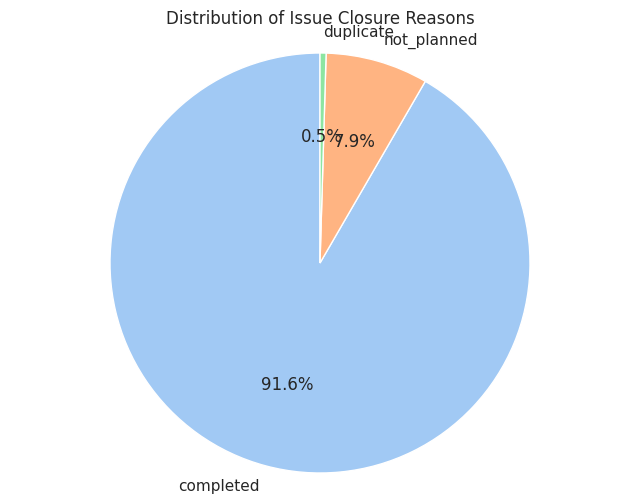

In [72]:
# --- Visualize the state_reason distribution ---
# Count closure reasons
counts = issue_df["state_reason"].value_counts()

# Create pie chart
plt.figure(figsize=(8, 6))
colors = sns.color_palette("pastel", len(counts))
plt.pie(
    counts,
    labels=counts.index,
    autopct="%1.1f%%",
    colors=colors,
    startangle=90
)

plt.title("Distribution of Issue Closure Reasons")
plt.axis("equal")
plt.show()

## RQ1 Findings

---

From the DataFrame and visualization above, we can identify three primary reasons why GitHub issues were closed:

1. **Completed**
2. **Not Planned**
3. **Duplicate**

The majority of closed issues fall under the **completed** category, accounting for 91.6% of all issues. In comparison, **not planned** issues represent a smaller proportion at 7.9%, while **duplicate** issues account for only 0.5%.

These findings indicate that the overwhelming majority of issues in the dataset were closed because they were completed, rather than being rejected, deprioritized, or identified as duplicates.

### Implications for Developers and Researchers

For developers, these findings suggest that most issue closures within the analyzed repositories are associated with completed work, potentially indicating that issue tracking is primarily used to manage and document development tasks through to completion. The relatively small proportion of issues closed as not planned or duplicates may also suggest that fewer issues are being dismissed or identified as redundant.

## RQ2
---

### GQM

Analyze closed software issues for the purpose of comparing closure reasons with respect to comment count and time-to-close from the point of view of software developers in the context of software development projects.


### Plan

To assess the comment count across the `issue_comments_df`, we will get the total number of unique comment_ids, which are linked to a specific comment



To assess the time-to-close across closure reasons, we will use the `issue_df` we will use the `time_to_close_hours`.

In [81]:
# --- Comment Count Across Closure Reasons ---
comment_counts_df = (
  issue_df.groupby("state_reason")["n_comments_actual"]
  .sum()
  .reset_index(name="total_comments")
)


,n_comments_actual
state_reason,
completed,705
duplicate,1
not_planned,20


In [82]:
time_to_close_df = (
    issue_df.groupby("state_reason")["time_to_close_hours"]
    .mean()
    .reset_index(name="avg_time_to_close_hours")
    .round(2)
)
time_to_close_df

,state_reason,avg_time_to_close_hours
0,completed,0.0
1,duplicate,0.0
2,not_planned,0.0


## RQ2 Findings

---

The results indicate a large difference in comment activity across the three closure reasons.

- **Completed:** 705 comments, accounting for approximately 97.1% of all recorded comments.
- **Not planned:** 20 comments, representing approximately 2.8%.
- **Duplicate:** 1 comment, representing approximately 0.1%.

These findings suggest that issues classified as completed account for the overwhelming majority of recorded discussion activity.

All three closure categories have an average time-to-close of 0.0 hours.

Although this initially suggests that issues are closed immediately, this result should likely be interpreted as a dataset limitation rather than an accurate representation of issue resolution times.

### Implications for Developers and Researchers

For developers, the findings suggest that completed issues account for most recorded comment activity, potentially reflecting greater discussion and collaboration during issue resolution. In contrast, issues closed as duplicates or not planned contribute relatively little to the overall comment activity. However, this does not necessarily indicate that individual completed issues require more discussion, as the number of issues in each closure category has not been considered.

## Threats to Validity

---

### 1. Construct Validity

Construct validity concerns whether the selected metrics accurately measure the concepts being investigated.

For RQ1, the `state_reason` attribute is used to identify why GitHub issues were closed. However, this attribute may not fully represent the underlying reasons for closure, as developers may close issues for reasons that are not adequately captured by the available categories (completed, not planned, and duplicate).

For RQ2, `n_comments_actual` is used to measure discussion activity. However, comment count does not necessarily reflect the quality or significance of developer discussions. Additionally, the `time_to_close_hours` attribute may not accurately represent actual issue resolution time, given that all closure categories produced an average of 0.0 hours. This suggests potential limitations in how the timestamps were recorded or calculated.

### 2. Internal Validity

Internal validity concerns whether the observed results are influenced by factors other than those being investigated.

A major threat arises from the dataset's missing values and the preprocessing decisions made to address them. Several columns contain over 70% missing values and were removed to avoid introducing bias through imputation.

Furthermore, rows containing missing `time_to_close_hours`, `api_closed_at`, or `state_reason` values were excluded from the analysis. While necessary for the research questions, removing these observations may introduce **selection bias**, as the remaining issues may not be representative of the original dataset.

In particular, removing approximately 75% of observations with missing `time_to_close_hours` significantly reduces the sample available for RQ2. If missing timestamps are associated with certain closure reasons, the resulting comparisons may be distorted.

### 3. External Validity

External validity concerns whether the findings can be generalized beyond the analyzed dataset.

The dataset contains 5,000 GitHub issues collected from a selection of repositories. Therefore, the observed distribution of closure reasons may not represent the behavior of all GitHub repositories or software development projects.

Different projects may follow different issue management practices, including how issues are categorized, discussed, and closed. Consequently, the finding that 91.6% of issues were closed as completed may be specific to the repositories included in the dataset.

Furthermore, the dataset combines GitHub Archive records with GitHub API information, which may represent different collection periods. This limits the ability to generalize the findings to other time periods or development environments.

### 4. Conclusion Validity

Conclusion validity concerns whether the conclusions drawn from the analysis are adequately supported by the available data.

- RQ1: The substantial imbalance between closure reasons (91.6% completed, 7.9% not planned, and 0.5% duplicate) means that conclusions regarding less common categories are based on relatively few observations. This limits the reliability of comparisons involving duplicate issues.

- RQ2: Completed issues account for 705 of the 726 recorded comments. However, these are total comment counts rather than average comments per issue. Therefore, the results cannot establish whether completed issues receive more discussion individually, since the number of issues within each category differs.

Additionally, the average time-to-close of 0.0 hours across all closure reasons prevents meaningful conclusions about differences in resolution time. Without validating the underlying timestamps, it would be inappropriate to conclude that issues are resolved immediately or that closure reasons have no relationship with resolution duration.

## Disclosure

---

No generative AI tools were used to draft, research, analyze, or revise this submission.